# Laboratório 8: Q-learning (CliffWalking)

## Importações

In [1]:
!pip install gymnasium[toy-text]                                                # CliffWalking e FrozenLake (inclui o pygame)
!pip install tqdm pandas seaborn                                                # Barra de progresso, tabelas e gráficos
!pip install gdown                                                              # Download do rl_utils.py e das figuras

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.1/12.1 MB 64.3 MB/s  0:00:00


In [2]:
import os                                                                       # Verificação de arquivos
import gdown                                                                    # Download de arquivos do Google Drive
from IPython.display import SVG, display                                        # Exibição das figuras (SVG)
import gymnasium as gym                                                         # Ambientes de aprendizado por reforço
from gymnasium.wrappers import RecordEpisodeStatistics                          # Estatísticas por episódio
import numpy as np                                                              # Operações numéricas e vetoriais
import pandas as pd                                                             # Tabelas de resultados
import matplotlib.pyplot as plt                                                 # Gráficos
from tqdm.auto import tqdm                                                      # Barra de progresso
from typing import NamedTuple, Optional, List, Tuple                            # Anotações de tipo e tuplas nomeadas
from collections import deque                                                   # Fila com tamanho máximo

## Funções auxiliares para visualização

In [3]:
RL_UTILS_URL = "https://drive.google.com/file/d/1AEJC-YWgeZCr8pZEOOiAg6PNK8IrBBRk/view?usp=sharing"

if not os.path.exists("rl_utils.py"):                                           # Baixa o módulo só se ainda não existir
    try:
        gdown.download(RL_UTILS_URL, "rl_utils.py", quiet=True, fuzzy=True)
    except Exception as error:
        print(f"Falha no download: {error}")

from rl_utils import (                                                          # Funções comuns aos labs da Unidade 2
    plot_results, plot_comparison,                                              # Curvas de treinamento
    simulate_trajectory, plot_trajectory,                                       # Trajetória sobre a grade
    show_one_episode,                                                           # Animação de um episódio
    plot_tabular, plot_policy_distributions,                                    # Mapas de calor de q, pi e v; barras pi(.|s)
)

In [4]:
FIGURE_URLS = {                                                                 # Links das figuras (SVG) no Google Drive
    "mapa_cliffwalking":
        "https://drive.google.com/file/d/1x1Poz-iZ3IcW-aLyYCwDMN7DPHlo5_So/view?usp=sharing",
    "env_step":
        "https://drive.google.com/file/d/1csEbTeLIz7a8-FDz0xwrd_M_T-_Z0Dj5/view?usp=sharing",
    "alvos_sarsa_qlearning":
        "https://drive.google.com/file/d/1vV29K0aDUBIeldPAOJ6mRJ7d67Uuh7_v/view?usp=sharing",
    "epsilon_gulosa":
        "https://drive.google.com/file/d/1LtJYLSN-zlitE6BMPHNTVoIuZcGcOymD/view?usp=sharing",
    "qlearning_passo":
        "https://drive.google.com/file/d/17R5xHWCJXk7oUfvzicc9lAZ32CMNM90e/view?usp=sharing",
}
FIGURE_DIR = "figuras"                                                          # Pasta local das figuras

os.makedirs(FIGURE_DIR, exist_ok=True)
for name, url in FIGURE_URLS.items():
    path = os.path.join(FIGURE_DIR, f"{name}.svg")
    if not os.path.exists(path):                                                # Baixa só se ainda não existir
        try:
            gdown.download(url, path, quiet=True, fuzzy=True)
        except Exception as error:
            print(f"Falha no download de {name}: {error}")


def show_figure(name: str) -> None:
    path = os.path.join(FIGURE_DIR, f"{name}.svg")
    try:
        display(SVG(filename=path))                                             # A figura aparece como saída da célula
    except Exception:                                                           # Arquivo ausente ou inválido
        print(f"Figura indisponível: {name}. Confira o link em FIGURE_URLS.")

## Ambiente: nova instância

O laboratório usa o `CliffWalking-v1`, do [Gymnasium](https://gymnasium.farama.org/environments/toy_text/cliff_walking/).

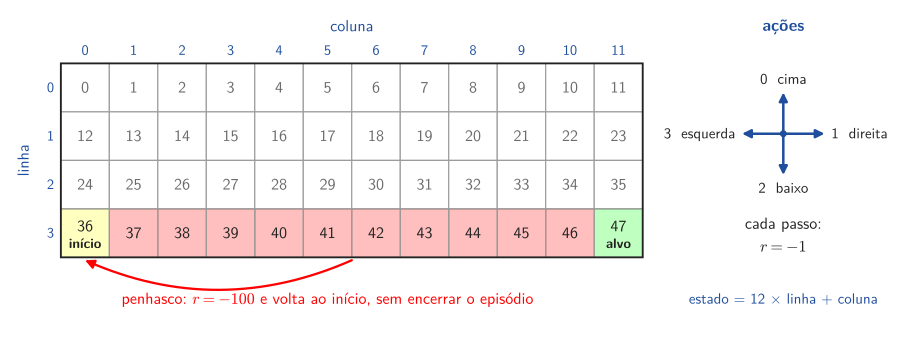

In [5]:
show_figure("mapa_cliffwalking")                                                # Mapa do CliffWalking

- **Estado:** o índice da célula, `12 * linha + coluna`, que é também a observação devolvida pelo ambiente.
- **Ações:** quatro; não há a ação de permanecer no lugar.
- **Recompensa:** $-1$ por passo. Quanto mais curto o caminho, maior a recompensa total, e o caminho mais curto passa rente ao penhasco.
- **Penhasco:** entrar nele custa $-100$ e devolve o agente a $s_0 = 36$, **sem** encerrar o episódio.
- **Fim do episódio:** há um estado terminal, o alvo. Como um agente que ainda não aprendeu pode vagar por muito tempo, o episódio também termina ao atingir um limite de passos.
- **Modelo:** não é usado. O agente aprende só com as amostras de experiência devolvidas por `env.step`, e não com um modelo como o `env.P` do FrozenLake (Laboratório 3).

A célula abaixo define as constantes e `make_env`, que cria o ambiente com o limite de passos e o envolve com o wrapper `RecordEpisodeStatistics`. Cada treinamento deve usar um ambiente novo, criado por `make_env`.

<details>
<summary><b>Detalhes:</b> <code>RecordEpisodeStatistics</code> </summary>

- No último passo de cada episódio, acrescenta a `info` a entrada `info["episode"]`, com:
  - `"r"`: a recompensa total, isto é, a soma das recompensas, sem desconto;
  - `"l"`: a duração, em passos;
  - `"t"`: o tempo de execução, em segundos.
- Guarda esses valores dos últimos `STATS_BUFFER_LENGTH` episódios nas filas `return_queue`, `length_queue` e `time_queue`, usadas nas médias da barra de progresso.
- Um ambiente novo começa com as filas vazias.

</details>

In [6]:
ENV_ID = "CliffWalking-v1"                                                      # Identificador do ambiente
MAX_EPISODE_STEPS = 500                                                         # Limite de passos por episódio
STATS_BUFFER_LENGTH = 100                                                       # Tamanho das filas e janela das médias
SEED = 42                                                                       # Semente para reprodutibilidade


def make_env(render_mode: Optional[str] = "rgb_array") -> gym.Env:
    env = gym.make(ENV_ID, render_mode=render_mode,                             # "rgb_array": render() devolve imagem
                   max_episode_steps=MAX_EPISODE_STEPS)                         # truncated = True no limite
    return RecordEpisodeStatistics(env, buffer_length=STATS_BUFFER_LENGTH)      # Registra r, l e t dos episódios


env = make_env()                                                                # Instância para inspeção

`env.reset` inicia um episódio e devolve o estado inicial $s_0$ e o dicionário `info`.

In [7]:
obs, info = env.reset(seed=SEED)                                                # Estado inicial s_0
obs, info

(36, {'prob': 1})

`env.render()` devolve a imagem do estado atual, um array com shape `(altura, largura, 3)`.

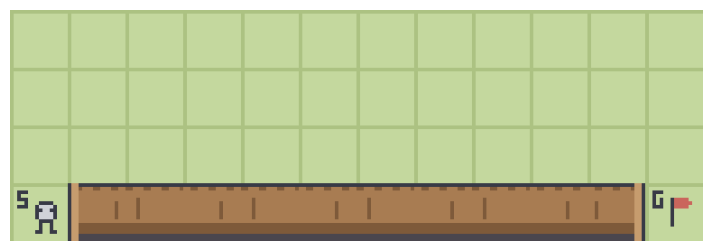

(256, 768, 3)

In [8]:
img = env.render()                                                              # Imagem RGB do estado atual
plt.figure(figsize=(9, 3))
plt.imshow(img)
plt.axis("off")
plt.show()
img.shape                                                                       # (altura, largura, canais)

`env.step` executa um passo. Ele recebe só a ação $a_t$, porque o ambiente já guarda o estado atual $s_t$:

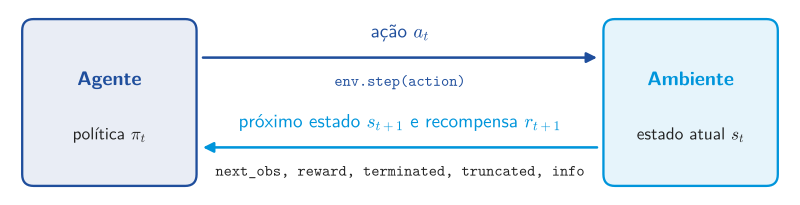

In [9]:
show_figure("env_step")                                                         # Interação agente-ambiente em env.step

| Saída | Nomenclatura | Significado |
|---|---|---|
| `next_obs` | $s_{t+1}$ | próximo estado |
| `reward` | $r_{t+1}$ | recompensa do passo |
| `terminated` | $s_{t+1}$ terminal | `True` ao chegar ao alvo: o episódio acaba, e $v(s_{t+1})=0$ |
| `truncated` | — | `True` ao atingir `MAX_EPISODE_STEPS`: o episódio para, mas $s_{t+1}$ **não** é terminal |
| `info` | — | dados auxiliares (`"prob"` e, no último passo, `"episode"`) |

> **Atenção:** $a_t$ não vem do ambiente: o agente a sorteia em $s_t$, com a política $\pi_t$, antes de chamar `env.step`.

A célula abaixo executa a ação `1` (direita) a partir de $s_0 = 36$, que leva ao penhasco. Observe `reward`, `next_obs` e `terminated`.

In [10]:
next_obs, reward, terminated, truncated, info = env.step(1)                     # Ação a_0 = 1 (direita) a partir de s_0
next_obs, reward, terminated, truncated, info

(36, -100, False, False, {'prob': 1.0})

A célula abaixo executa um episódio com ações sorteadas uniformemente por `env.action_space.sample()`. Agindo ao acaso, o agente dificilmente alcança o alvo, e o episódio costuma acabar por truncamento; no último passo, `info["episode"]` traz as estatísticas do wrapper.

In [11]:
env.action_space.seed(SEED)                                                     # Fixa o sorteio das ações aleatórias
obs, info = env.reset(seed=SEED)
episode_over = False
while not episode_over:                                                         # Um episódio com ações aleatórias
    action = env.action_space.sample()                                          # Ação sorteada uniformemente
    obs, reward, terminated, truncated, info = env.step(action)
    episode_over = terminated or truncated                                      # Alvo ou limite de passos
terminated, truncated, info["episode"]

(False, True, {'r': -5945.0, 'l': 500, 't': 0.020116})

## Algoritmo: Q-learning

O Q-learning escolhe as ações com uma política $\epsilon$-gulosa e corrige a estimativa do par visitado $(s_t, a_t)$ **a cada passo**, como o Sarsa do Laboratório 7, mas com outro alvo TD: no lugar do valor da ação seguinte, entra o maior valor de ação em $s_{t+1}$. Com isso, $q$ estima diretamente os **valores de ação ótimos**:

$$
\underbrace{q_{t+1}(s_t,a_t)}_{\substack{\text{nova}\\ \text{estimativa}}}
\;=\;
\underbrace{q_t(s_t,a_t)}_{\substack{\text{estimativa}\\ \text{atual}}}
\;-\;
\underbrace{\alpha}_{\substack{\text{taxa de}\\ \text{aprendizado}}}
\,
\underbrace{\Big[\, q_t(s_t,a_t) \;-\; {\color{red}{\overbrace{r_{t+1} + \gamma \max_{a \in \mathcal{A}(s_{t+1})} q_t(s_{t+1},a)}^{\text{alvo TD: } \bar q_t}}} \,\Big]}_{\text{erro TD: } \delta_t}
$$

- $q_t(s,a)$ é a estimativa do valor de ação ótimo de $(s,a)$ no passo $t$, e só o par visitado muda: $q_{t+1}(s,a) = q_t(s,a)$ para todo $(s,a) \neq (s_t,a_t)$.
- Se $s_{t+1}$ é terminal, o futuro vale zero e o alvo é só $\bar q_t = r_{t+1}$.
- Cada atualização usa só $(s_t, a_t, r_{t+1}, s_{t+1})$: a próxima ação não entra no alvo.

<details>
<summary><b>Detalhes:</b> a equação que o Q-learning resolve</summary>

O alvo $\bar q_t$ é uma amostra do lado direito da equação de otimalidade de Bellman, escrita com valores de ação:

$$q(s,a) = \mathbb{E}\Big[R_{t+1} + \gamma \max_{a} q(S_{t+1},a) \,\Big|\, S_t = s, A_t = a\Big]$$

A solução dessa equação são os valores de ação ótimos. O Sarsa resolve a equação de Bellman da política seguida, $q_\pi(s,a) = \mathbb{E}[R_{t+1} + \gamma\, q_\pi(S_{t+1},A_{t+1}) \mid S_t = s, A_t = a]$, e por isso estima os valores dessa política.

</details>

A diferença para o Sarsa está no termo de bootstrap do alvo:

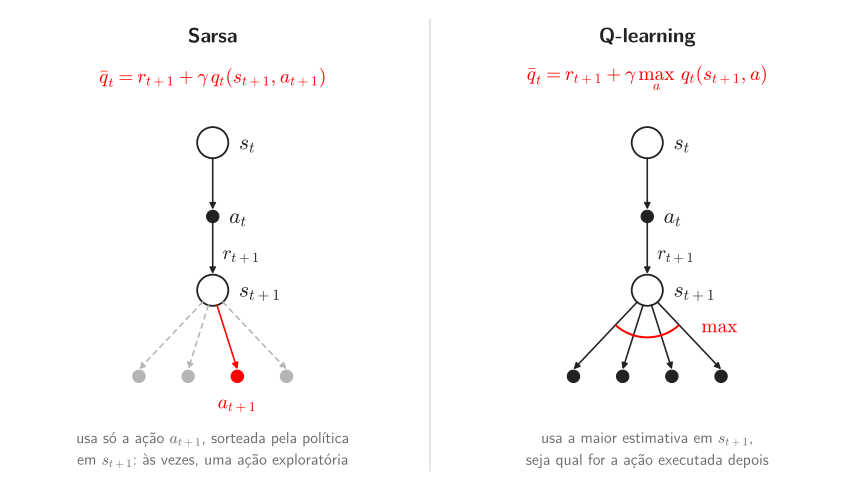

In [12]:
show_figure("alvos_sarsa_qlearning")                                            # Termo de bootstrap no Sarsa e no Q-learning

**Cada iteração tem dois passos**:

1. **Valor de ação:** atualiza $q(s_t, a_t)$ pela equação acima.
2. **Política:** atualiza a política em $s_t$, que passa a ser $\epsilon$-gulosa em relação às estimativas atualizadas:

$$
\pi_{t+1}(a \mid s_t) =
\begin{cases}
1 - \dfrac{\epsilon}{|\mathcal{A}(s_t)|}\big(|\mathcal{A}(s_t)| - 1\big), & \text{se } a = \arg\max\limits_{a} q_{t+1}(s_t,a) \\[10pt]
\dfrac{\epsilon}{|\mathcal{A}(s_t)|}, & \text{caso contrário}
\end{cases}
$$

Com $\epsilon = 0.1$ e as quatro ações do CliffWalking:

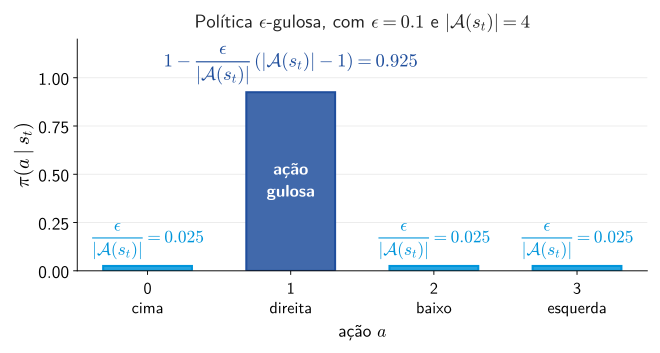

In [13]:
show_figure("epsilon_gulosa")                                                   # Política epsilon-gulosa com epsilon = 0.1

> **Atenção:** em relação ao Sarsa, só o alvo muda. As ações continuam sendo escolhidas pela política $\epsilon$-gulosa, mas o alvo usa a estimativa da melhor ação em $s_{t+1}$, seja qual for a ação que o agente escolher depois.

**Implementação.** Preencha os blocos marcados:

| Parte | Descrição | A implementar |
|---|---|---|
| `Params` | reúne os hiperparâmetros | — |
| `QLearningAgent` | guarda $q$, $\pi$ e as contagens de visitas; sorteia as ações; executa os dois passos | `update_policy`, `get_target_value` e `update_Q` |
| `run_episode_and_train` | executa um episódio, atualizando o agente a cada passo | o laço |
| `train_agent` | repete os episódios e registra as métricas | — |

### Hiperparâmetros

`Params` reúne os hiperparâmetros; `n_states` e `n_actions` vêm do ambiente.

| Campo | Hiperparâmetro |
|---|---|
| `n_episodes` | número de episódios, $N$ |
| `learning_rate` | taxa de aprendizado, $\alpha$ |
| `discount_factor` | fator de desconto, $\gamma$ |
| `epsilon` | parâmetro $\epsilon$ da política |

<details>
<summary><b>Detalhes:</b> como variar um hiperparâmetro com <code>_replace</code></summary>

Uma `NamedTuple` não pode ser alterada depois de criada, mas `params._replace(learning_rate=0.5)` devolve uma cópia de `params` com $\alpha$ trocado. Isso facilita variar um hiperparâmetro de cada vez, como nos itens 1 a 5 da tarefa.

</details>

In [14]:
class Params(NamedTuple):
    n_states: int                                                               # Número de estados |S|
    n_actions: int                                                              # Número de ações |A|
    n_episodes: int                                                             # Número de episódios (N)
    learning_rate: float                                                        # Taxa de aprendizado (alpha)
    discount_factor: float                                                      # Fator de desconto (gamma)
    epsilon: float                                                              # Parâmetro da política epsilon-gulosa

### Agente

Implemente `update_policy`, `get_target_value` e `update_Q`; os demais métodos já estão prontos. O agente guarda:

| Atributo | Conteúdo |
|---|---|
| `self.Q` | estimativas $q_t(s,a)$ dos valores de ação ótimos, inicializada com zeros |
| `self.Pi` | política $\pi_t(a \mid s)$, inicializada uniformemente; a linha `self.Pi[s]` é o vetor de probabilidades das ações em `s` |
| `self.visit_counts` | número de visitas a cada par $(s,a)$ |
| `self.learning_rate`, `self.discount_factor`, `self.epsilon` | $\alpha$, $\gamma$, $\epsilon$ |
| `self.rng` | gerador de números aleatórios do agente |

As três matrizes têm shape `(n_states, n_actions)` e são indexadas por `[estado, ação]`. Nos métodos, os argumentos correspondem a:

| `obs` | `action` | `reward` | `next_obs` | `terminated` |
|:---:|:---:|:---:|:---:|:---:|
| $s_t$ | $a_t$ | $r_{t+1}$ | $s_{t+1}$ | $s_{t+1}$ é terminal? |

<details>
<summary><b>Detalhes:</b> métodos prontos</summary>

- `get_greedy_action(obs)`: devolve $\arg\max_a q_t(s,a)$; em caso de empate, a ação de menor índice.
- `sample_action(obs)`: sorteia $a_t$ com as probabilidades de `self.Pi[obs]`, usando `self.rng`, e devolve `(action, is_exploratory)`, em que `is_exploratory` é `1` se a ação sorteada difere da gulosa e `0` caso contrário.
- `update(...)`: chama `update_Q` e `update_policy` e registra a visita ao par $(s_t, a_t)$.
- `policy(obs, deterministic)`: devolve a ação gulosa ou sorteia uma ação $\epsilon$-gulosa; é usado nas visualizações.

</details>

**A implementar:**

- `update_policy(obs)` $\to$ não devolve nada; atualiza a linha `self.Pi[obs]`, o passo 2, pela fórmula $\epsilon$-gulosa da seção **Algoritmo**:
  - a ação gulosa recebe $1 - \dfrac{\epsilon}{|\mathcal{A}(s_t)|}\big(|\mathcal{A}(s_t)| - 1\big)$;
  - cada uma das demais ações recebe $\dfrac{\epsilon}{|\mathcal{A}(s_t)|}$, com $|\mathcal{A}(s_t)|$ = `self.n_actions`.
- `get_target_value(next_obs, reward, terminated)` $\to$ o alvo $\bar q_t$, um número real:
  - $\bar q_t = r_{t+1} + \gamma \max_a q_t(s_{t+1},a)$, ou só $r_{t+1}$ se $s_{t+1}$ é terminal;
  - a linha `self.Q[next_obs]` traz as estimativas das quatro ações em $s_{t+1}$.
- `update_Q(obs, action, next_obs, reward, terminated)` $\to$ o erro TD $\delta_t$, um número real (escalar):
  - calcula o alvo com `get_target_value` e o erro TD: $\delta_t = q_t(s_t,a_t) - \bar q_t$;
  - atualiza o par visitado: $q_{t+1}(s_t,a_t) = q_t(s_t,a_t) - \alpha\,\delta_t$.

> **Atenção:**
> - Só `terminated` zera o futuro. No truncamento, $s_{t+1}$ não é terminal e $\gamma \max_a q_t(s_{t+1},a)$ continua no alvo; por isso os métodos não recebem `truncated`.
> - Em `update_policy`, obtenha a ação gulosa com `self.get_greedy_action(obs)`: é a mesma que `sample_action` usa para marcar as ações exploratórias.

In [ ]:
class QLearningAgent:
    def __init__(self, params: Params, seed: int = SEED):
        self.n_states = params.n_states                                         # Número de estados
        self.n_actions = params.n_actions                                       # Número de ações
        self.learning_rate = params.learning_rate                               # alpha
        self.discount_factor = params.discount_factor                           # gamma
        self.epsilon = params.epsilon                                           # epsilon
        self.rng = np.random.default_rng(seed)                                  # Gerador aleatório do agente
        shape = (self.n_states, self.n_actions)
        self.Q = np.zeros(shape)                                                # Estimativas q_t(s,a)
        self.Pi = np.full(shape, 1.0 / self.n_actions)                          # Política inicial uniforme
        self.visit_counts = np.zeros(shape)                                     # Visitas a cada par (s,a)


    def get_greedy_action(self, obs: int) -> int:
        return int(np.argmax(self.Q[obs]))                                      # argmax_a q_t(s,a); empate: menor índice


    def update_policy(self, obs: int) -> None: # Passo 2: pi(.|s_t) epsilon-gulosa
        greedy_action = self.get_greedy_action(obs)
        base = self.epsilon / self.n_actions
        calc = (1 - self.epsilon) + base
    
        self.Pi[obs] = base
        self.Pi[obs, greedy_action] = calc
    

    def sample_action(self, obs: int) -> Tuple[int, int]:
        action = int(self.rng.choice(self.n_actions, p=self.Pi[obs]))           # a_t ~ pi_t(.|s_t)
        is_exploratory = int(action != self.get_greedy_action(obs))             # 1 se a ação não é a gulosa
        return action, is_exploratory


    def policy(self, obs: int, deterministic: bool = False) -> int:
        if deterministic:
            return self.get_greedy_action(obs)                                  # Gulosa (sem exploração)
        return self.sample_action(obs)[0]                                       # epsilon-gulosa (com exploração)


    def get_target_value(self, next_obs: int, reward: float, terminated: bool) -> float: # Alvo TD (ver a célula acima)
        if terminated:
            target_value = reward
        else:
            target_value = reward + (self.discount_factor * np.max(self.Q[next_obs]))
        return target_value


    def update_Q(self, obs: int, action: int, next_obs: int, reward: float,
                 terminated: bool) -> float:
        target_value = self.get_target_value(next_obs, reward, terminated)
        td_error = self.Q[obs, action] - target_value
        self.Q[obs, action] -= self.learning_rate * td_error
        return td_error


    def update(self, obs: int, action: int, next_obs: int, reward: float,
               terminated: bool) -> None:
        self.update_Q(obs, action, next_obs, reward, terminated)                # 1. Valor de ação
        self.update_policy(obs)                                                 # 2. Política em s_t
        self.visit_counts[obs, action] += 1                                     # Visita ao par (s_t, a_t)


### Episódio de treinamento

Implemente o laço de `run_episode_and_train`. O início já está pronto: `env.reset` devolve $s_0$. Cada iteração do laço segue os passos da figura:

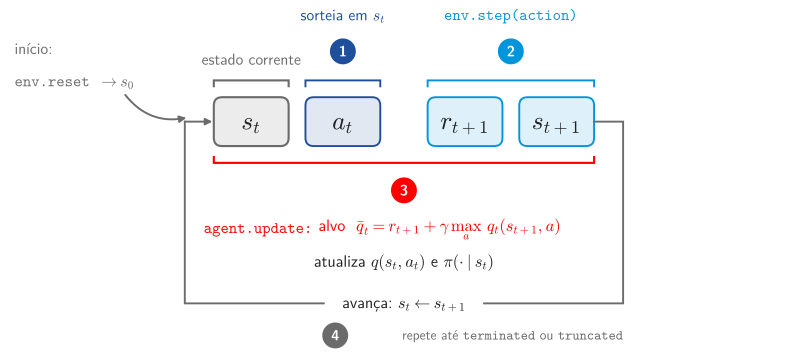

In [16]:
show_figure("qlearning_passo")                                                  # Um passo do Q-learning

1. sorteia $a_t$ em $s_t$, com a política $\epsilon$-gulosa, chamando `agent.sample_action`;
2. executa $a_t$ com `env.step`, que devolve $r_{t+1}$ e $s_{t+1}$;
3. atualiza o agente com $(s_t, a_t, r_{t+1}, s_{t+1})$, chamando `agent.update`;
4. avança: $s_t \leftarrow s_{t+1}$.

O laço termina quando `terminated` ou `truncated` é `True`.

> **Atenção:**
> - Não há $a_{t+1}$ no laço: o alvo não a usa, e a ação do passo seguinte é sorteada no início dele, com a política já atualizada.
> - Passe `terminated` ao agente, e **não** `terminated or truncated`.
> - Some em `n_exploratory_actions` o `is_exploratory` de cada ação executada.

**Retorno** (já pronto):

- `info["episode"]`: recompensa total, duração e tempo do episódio;
- `n_exploratory_actions`: número de ações não gulosas executadas;
- `terminated`: o sinal do último passo.

In [17]:
def run_episode_and_train(agent: QLearningAgent, env: gym.Env, seed: int = SEED):
    obs, _info = env.reset(seed=seed)                                           # s_0

    episode_over = False                                                        # Fim do episódio
    n_exploratory_actions = 0                                                   # Ações não gulosas executadas
    terminated = False                                                          # Sinal de estado terminal
    info = {}                                                                   # Informações do último passo

    while not episode_over:
        action, is_exploratory = agent.sample_action(obs)
        n_exploratory_actions += is_exploratory
        next_obs, reward, terminated, truncated, info = env.step(action)
        agent.update(obs, action, next_obs, reward, terminated)
        obs = next_obs
        episode_over = terminated or truncated

    return info["episode"], n_exploratory_actions, terminated                   # Estatísticas, exploração e término


### Laço externo

`train_agent` já está pronta. Ela repete `run_episode_and_train` por `n_episodes` episódios, cada um com uma semente sorteada pelo gerador do agente, e devolve as séries numa `TrainingHistory`:

| Campo | Série, por episódio |
|---|---|
| `returns` | recompensa total |
| `lengths` | duração, em passos |
| `times` | tempo de execução, em segundos |
| `exploration_rates` | proporção de ações não gulosas executadas |
| `successes` | 1 se o episódio terminou no alvo; como o alvo é o único estado terminal do CliffWalking, o sucesso é o próprio `terminated` |

A barra de progresso mostra as médias dos últimos `STATS_BUFFER_LENGTH` episódios, calculadas com as filas do `RecordEpisodeStatistics`. O argumento opcional `run_episode` troca a função que executa cada episódio; ele só é usado no item 5 da tarefa, para treinar o Sarsa com o laço dele.

<details>
<summary><b>Detalhes:</b> a tupla nomeada <code>TrainingHistory</code></summary>

Cada campo pode ser acessado pelo nome, como em `history.returns`, e a tupla também pode ser desempacotada na ordem em que os campos foram definidos.

</details>

In [18]:
class TrainingHistory(NamedTuple):
    returns: List[float]                                                        # Recompensa total (sem desconto) por episódio
    lengths: List[int]                                                          # Duração (passos) por episódio
    times: List[float]                                                          # Tempo de execução (s) por episódio
    exploration_rates: List[float]                                              # Proporção de ações exploratórias
    successes: List[int]                                                        # 1 se terminou no alvo, 0 caso contrário


def train_agent(agent, env: gym.Env, n_episodes: int,
                run_episode=None) -> TrainingHistory:
    if run_episode is None:                                                     # Padrão: o laço do Q-learning
        run_episode = run_episode_and_train
    returns, lengths, times, exploration_rates, successes = [], [], [], [], []  # Históricos por episódio
    success_queue = deque(maxlen=env.return_queue.maxlen)                       # Janela recente de sucessos
    pbar = tqdm(range(n_episodes), desc="Treinando", unit="episódio")           # Barra de progresso

    for episode in pbar:
        seed = int(agent.rng.integers(2**32))                                   # Semente do episódio
        episode_data, n_exploratory_actions, terminated = run_episode(
            agent=agent, env=env, seed=seed)                                    # Treina em um episódio

        episode_length = int(episode_data["l"])                                 # Número de passos
        exploration_rate = n_exploratory_actions / episode_length               # Proporção de ações exploratórias
        success = int(terminated)                                               # No CliffWalking, terminar = chegar ao alvo

        returns.append(float(episode_data["r"]))                                # Recompensa total
        lengths.append(episode_length)                                          # Duração
        times.append(float(episode_data["t"]))                                  # Tempo
        exploration_rates.append(exploration_rate)                              # Exploração
        successes.append(success)                                               # Sucesso
        success_queue.append(success)                                           # Fila de sucessos recentes

        pbar.set_postfix({                                                      # Médias recentes na barra
            "recompensa_media": f"{np.mean(env.return_queue):.1f}",
            "passos_medio": f"{np.mean(env.length_queue):.1f}",
            "tempo_medio": f"{np.mean(env.time_queue):.3f}",
            "exploracao": f"{exploration_rate:.3f}",
            "sucesso": f"{np.mean(success_queue):.3f}",
        })

    return TrainingHistory(returns, lengths, times, exploration_rates, successes)

## Experimento

### Simulação

A célula abaixo treina o Q-learning na configuração base, com um ambiente (`train_env`) e um agente novos. O gerador do agente controla todos os sorteios e o CliffWalking é determinístico: com a mesma semente, a execução é reprodutível.

In [19]:
params = Params(
    n_states=env.observation_space.n,                                           # 48 estados
    n_actions=env.action_space.n,                                               # 4 ações
    n_episodes=1000,                                                            # Número de episódios (N)
    learning_rate=0.1,                                                          # Taxa de aprendizado (alpha)
    discount_factor=0.9,                                                        # Fator de desconto (gamma)
    epsilon=0.1,                                                                # Parâmetro da política epsilon-gulosa
)

train_env = make_env()                                                          # Ambiente novo para o treinamento
agent = QLearningAgent(params, seed=SEED)                                       # Agente novo, com a semente do experimento
history = train_agent(agent, train_env, params.n_episodes)

Treinando:   0%|          | 0/1000 [00:00<?, ?episódio/s]

NotImplementedError: remova esta linha ao implementar

Como $q$ estima os valores de ação ótimos, os valores de estado saem do valor da melhor ação em cada estado:

$$v(s) = \max_a q(s,a)$$

In [ ]:
V = np.max(agent.Q, axis=1)                                                     # v(s) = max_a q(s,a)

### Avaliação da política $\epsilon$-gulosa

O Q-learning estima os valores de ação ótimos, mas, no treinamento, as ações são escolhidas por uma política $\epsilon$-gulosa em relação aos valores de ação estimados, guardada em `agent.Pi`. `evaluate_policy`, já pronta, mede o desempenho dessa política, com exploração: executa `n_episodes` episódios (100, por padrão) num ambiente novo, criado por `make_env`, sorteando cada ação com as probabilidades de `agent.Pi`, **sem** atualizar $q$ nem $\pi$. Ela devolve:

| Métrica | Significado |
|---|---|
| `chegada ao alvo` | proporção dos episódios que terminam no alvo |
| `recompensa total média` | média da recompensa total dos episódios |
| `duração média` | média da duração dos episódios, em passos |

Os sorteios usam um gerador próprio, criado com `seed`.

> **Atenção:** as curvas de `plot_results` vêm do treinamento, em que a política muda a cada atualização, inclusive dentro de um episódio. Elas mostram como o agente aprendeu; o desempenho da política $\epsilon$-gulosa ao fim do treinamento é o que `evaluate_policy` mede, com $q$ e $\pi$ fixos.

In [ ]:
def evaluate_policy(agent, n_episodes: int = 100, seed: int = SEED) -> pd.Series:
    rng = np.random.default_rng(seed)                                           # Gerador próprio da avaliação
    eval_env = make_env(render_mode=None)                                       # Ambiente novo, com o limite de passos
    returns, lengths, successes = [], [], []

    for _ in range(n_episodes):
        obs, _info = eval_env.reset(seed=int(rng.integers(2**32)))              # s_0
        terminated = truncated = False
        while not (terminated or truncated):
            action = int(rng.choice(agent.n_actions, p=agent.Pi[obs]))          # a ~ pi(.|s), epsilon-gulosa em relação a q
            obs, _reward, terminated, truncated, info = eval_env.step(action)   # Sem agent.update: q e pi fixos
        returns.append(float(info["episode"]["r"]))                             # Recompensa total
        lengths.append(int(info["episode"]["l"]))                               # Duração
        successes.append(int(terminated))                                       # 1 se chegou ao alvo

    return pd.Series({
        "chegada ao alvo": np.mean(successes),
        "recompensa total média": np.mean(returns),
        "duração média": np.mean(lengths),
    })

Na configuração base:

In [ ]:
evaluate_policy(agent)                                                          # Política epsilon-gulosa, com q e pi fixos

### Visualização

As figuras vêm das funções do `rl_utils`, importadas no início do notebook:

| Função | Descrição |
|---|---|
| `plot_results` | recompensa total, duração, taxa de exploração e sucesso por episódio, com a média móvel de `STATS_BUFFER_LENGTH` episódios |
| `simulate_trajectory` | executa um episódio num ambiente próprio e devolve a trajetória; por padrão, a trajetória gulosa (definida abaixo) |
| `plot_trajectory` | o caminho sobre a grade, com o penhasco em vermelho e o alvo em verde |
| `show_one_episode` | a animação de um episódio com a política $\epsilon$-gulosa, exploração incluída |
| `plot_tabular` | mapas de calor de $q(s,a)$, $\pi(a \mid s)$ ou $v(s)$, escolhidos pelo argumento `kind` |
| `plot_policy_distributions` | as probabilidades das quatro ações em cada estado |
| `plot_comparison` | as médias móveis de várias execuções num só gráfico, com legenda (usada na tarefa) |

> **Atenção:** cada mapa de calor calcula a escala de cores a partir dos próprios valores, e a mesma cor pode representar números diferentes em figuras diferentes. Para comparar figuras, use os números anotados nas células.

<details>
<summary><b>Detalhes:</b> escalas dos eixos e gráficos lado a lado</summary>

- Em `plot_results` e `plot_comparison`, o eixo da recompensa total usa a escala `symlog` quando há valores abaixo de $-100$: linear entre $-100$ e $100$ e logarítmica fora dessa faixa. O eixo da duração usa a escala logarítmica quando a duração varia muito. Nos demais casos, a escala é linear.
- `plot_comparison` e `plot_trajectory` aceitam o argumento `ax`, o painel da figura em que o gráfico é desenhado. Com `ax`, elas não chamam `plt.show()`, e a figura é exibida uma vez só, ao final. Para as curvas de duração e de recompensa total lado a lado:

      fig, axs = plt.subplots(1, 2, figsize=(18, 5))
      plot_comparison(histories, metric="lengths", ax=axs[0])
      plot_comparison(histories, metric="returns", ax=axs[1])
      plt.tight_layout()
      plt.show()

  em que `histories` é um dicionário que associa o rótulo de cada configuração (o texto da legenda) ao histórico devolvido por `train_agent`.

</details>

In [ ]:
df_results = plot_results(                                                      # Métricas da configuração base
    history.returns, history.lengths, history.exploration_rates,
    history.successes, window=STATS_BUFFER_LENGTH)

**Trajetória gulosa:** a trajetória obtida executando, em cada estado, a ação de maior valor estimado, $\arg\max_a q(s,a)$, sem exploração. Ela mostra o caminho indicado pelos valores de ação aprendidos; o desempenho com exploração é o da política $\epsilon$-gulosa, medido por `evaluate_policy`. Com $\epsilon = 0.1$, a política $\epsilon$-gulosa escolhe a ação gulosa com probabilidade 0.925 em cada estado.

In [ ]:
states, actions, rewards = simulate_trajectory(agent, ENV_ID)                   # Trajetória gulosa (sem exploração)
title = (f"Trajetória gulosa: {len(actions)} passos, "
         f"recompensa total {sum(rewards):.0f}")
_ = plot_trajectory(ENV_ID, states, title=title)

In [ ]:
show_one_episode(agent.policy, ENV_ID, seed=SEED)                               # Animação com a política epsilon-gulosa

In [ ]:
_ = plot_tabular(agent.Q, kind="Q")                                             # q: ndarray (n_estados, n_acoes)

In [ ]:
_ = plot_tabular(agent.Pi, kind="Pi")                                           # pi: ndarray (n_estados, n_acoes)

In [ ]:
_ = plot_tabular(V, kind="V", env_id=ENV_ID, center_zero=False)                 # v: ndarray (n_estados,)

In [ ]:
plot_policy_distributions(agent.Pi, ENV_ID)                                     # pi(.|s) em cada estado

# Tarefa (em trios):

Responda no próprio notebook. Cada item tem uma seção **Resposta**, com:

- uma célula de código, para os experimentos, as figuras e as tabelas;
- uma célula de texto, com **uma resposta por pergunta**, identificada pelo mesmo rótulo: (a), (b), ...

Acrescente células se precisar, mas não apague nem reordene os enunciados.

**Configuração base (baseline)**

| Parâmetro | Valor |
|---|---|
| ambiente | `CliffWalking-v1`, com `MAX_EPISODE_STEPS = 500` |
| número de episódios, $N$ | `n_episodes = 1000` |
| taxa de aprendizado, $\alpha$ | `learning_rate = 0.1` |
| fator de desconto, $\gamma$ | `discount_factor = 0.9` |
| parâmetro $\epsilon$ | `epsilon = 0.1` |
| janela das médias móveis | `STATS_BUFFER_LENGTH = 100` episódios |
| semente | `SEED = 42`, com ambiente (`make_env`) e agente novos em cada execução |

São os mesmos valores do Laboratório 7, para que o item 5 possa comparar o Q-learning com o Sarsa.

**Mostrar**

- **Figuras:**
  - configuração base: as figuras da seção **Visualização** (curvas de `plot_results`, trajetória gulosa e mapas de calor de $q(s,a)$, $\pi(a \mid s)$ e $v(s)$);
  - itens 1 a 4: as curvas de duração e de recompensa total de todas as execuções do item, sobrepostas e com legenda (`plot_comparison`), e a trajetória gulosa de cada execução;
  - item 5: para cada valor de $\epsilon$, as curvas de duração e de recompensa total do Sarsa e do Q-learning, sobrepostas e com legenda, e a trajetória gulosa de cada algoritmo.
- **Tabela**, para cada execução dos itens 1 a 5:
  - chegada ao alvo, recompensa total média e duração média da política $\epsilon$-gulosa, medidas com `evaluate_policy`;
  - passos e recompensa total da trajetória gulosa.
- **Discussão:** uma resposta curta por pergunta, na célula de texto da **Resposta**.

**Entregáveis**

- Um notebook (`.ipynb`) por laboratório da Unidade 2, entregue ao fim da unidade, com a tarefa respondida nas seções **Resposta**. Nesta unidade não há relatório em PDF.
- O notebook deve **executar do início ao fim sem erros** em um kernel novo (*Restart & Run All*), com as saídas exibidas correspondendo a essa execução. Notebooks que não executarem por completo serão penalizados.
- A entrega é **única por grupo**, com os integrantes identificados no início do notebook.

## 0. Implementação

**Experimento:** implemente `update_policy`, `get_target_value` e `update_Q` de `QLearningAgent` e o laço de `run_episode_and_train`, e execute a seção **Experimento**: treinamento na configuração base, avaliação da política $\epsilon$-gulosa e visualização.

**Perguntas:**

- **(a)** Compare a trajetória gulosa com o caminho mais curto (13 passos, rente ao penhasco). O que, na forma como o Q-learning calcula o alvo TD $\bar q_t$, explica o caminho aprendido?
- **(b)** Compare a recompensa total da trajetória gulosa com a recompensa total média de uma política $\epsilon$-gulosa em relação aos valores de ação estimados, medida com `evaluate_policy`. Por que são diferentes?

### Resposta

In [ ]:
# Tabela de métricas para a configuração base
df_base_eval = evaluate_policy(agent)
states, actions, rewards = simulate_trajectory(agent, ENV_ID)
table_base = pd.DataFrame([{
    "Configuração": "Baseline (α=0.1, γ=0.9, ε=0.1, N=1000)",
    "Chegada ao alvo (ε-gulosa)": df_base_eval["chegada ao alvo"],
    "Recompensa média (ε-gulosa)": df_base_eval["recompensa total média"],
    "Duração média (ε-gulosa)": df_base_eval["duração média"],
    "Passos (gulosa)": len(actions),
    "Recompensa (gulosa)": sum(rewards),
}])
display(table_base)


- **(a)** A trajetória gulosa obtida pelo agente coincide exatamente com o caminho mais curto possível no ambiente (13 passos e recompensa total de hBc13$): sobe um passo, percorre 11 passos para a direita na linha 2 (rente à borda do penhasco) e desce no alvo. Isso se explica pela natureza **off-policy** do Q-learning: seu alvo TD $\bar q_t = r_{t+1} + \gamma \max_a q_t(s_{t+1}, a)$ assume que a partir do próximo estado o agente sempre executará a melhor ação possível, ignorando que a política real de comportamento é $\epsilonhBcgulosa e está sujeita a desvios exploratórios. Por não computar o risco de quedas futuras no alvo, o Q-learning aprende a rota teoricamente ótima.

- **(b)** A recompensa da trajetória gulosa é de hBc13$, enquanto a média da política $\epsilonhBcgulosa medida por  é muito inferior (em torno de hBc50$ a hBc70$). A diferença ocorre porque a trajetória gulosa é 100% determinística ($\epsilon = 0$), executando a rota na borda sem cometer erros e sem nunca cair no penhasco. Já na política $\epsilonhBcgulosa, há probabilidade $\epsilon = 0.1$ de tomar uma ação aleatória a cada passo; como a rota ótima passa encostada no penhasco, basta um único passo acidental para baixo para o agente cair, receber a severa penalidade de hBc100$ e reiniciar da origem, o que derruba a média.

## 1. Efeito da taxa de aprendizado ($\alpha$)

**Experimento:** treine o Q-learning para $\alpha \in \{0.01,\ 0.1,\ 0.5,\ 1.0\}$, com um ambiente e um agente novos para cada valor, fixando:

- $\gamma = 0.9$;
- $\epsilon = 0.1$;
- `n_episodes = 1000`;
- os demais parâmetros do baseline.

Crie os parâmetros de cada execução a partir do baseline com `_replace`:

    params_exp = params._replace(learning_rate=0.5)

**Perguntas:**

- **(a)** Como $\alpha$ afetou o aprendizado?

### Resposta

In [ ]:
alphas = [0.01, 0.1, 0.5, 1.0]
histories_alpha = {}
results_alpha = []

for alpha in alphas:
    label = f"α = {alpha}"
    params_exp = params._replace(learning_rate=alpha)
    agent_exp = QLearningAgent(params_exp)
    env_exp = make_env()
    history_exp = train_agent(agent_exp, env_exp, params_exp.n_episodes)
    histories_alpha[label] = history_exp
    
    eval_series = evaluate_policy(agent_exp)
    states, actions, rewards = simulate_trajectory(agent_exp, ENV_ID)
    plot_trajectory(ENV_ID, states, title=f"Trajetória gulosa ({label}): {len(actions)} passos, recompensa {sum(rewards):.0f}")
    
    results_alpha.append({
        "alpha": alpha,
        "Chegada ao alvo (ε-gulosa)": eval_series["chegada ao alvo"],
        "Recompensa média (ε-gulosa)": eval_series["recompensa total média"],
        "Duração média (ε-gulosa)": eval_series["duração média"],
        "Passos (gulosa)": len(actions),
        "Recompensa (gulosa)": sum(rewards),
    })

plot_comparison(histories_alpha, metric="returns", title="Retorno médio por episódio para diferentes valores de α")
plot_comparison(histories_alpha, metric="lengths", title="Duração média por episódio para diferentes valores de α")
df_alpha = pd.DataFrame(results_alpha)
display(df_alpha)


- **(a)** A taxa de aprendizado $\alpha$ controla a velocidade e a estabilidade da atualização dos valores $:
  - Para $\alpha = 0.01$, o aprendizado é excessivamente lento; em 1000 episódios o agente atualiza pouco os valores a cada visita e não consegue convergir adequadamente.
  - Para $\alpha = 0.1$ (baseline), há um equilíbrio ideal: a convergência é rápida, estável e o agente aprende consistentemente o caminho ótimo de 13 passos.
  - Para $\alpha = 0.5$ e $\alpha = 1.0$, o aprendizado inicial é bastante veloz, porém as estimativas sofrem com alta variância e oscilações ao longo de todo o treinamento, pois cada passo substitui bruscamente o valor anterior pela recompensa observada no passo recente.

## 2. Efeito do fator de desconto ($\gamma$)

**Experimento:** treine o Q-learning para $\gamma \in \{0,\ 0.5,\ 0.9,\ 0.99\}$, com um ambiente e um agente novos para cada valor, fixando:

- $\alpha = 0.1$;
- $\epsilon = 0.1$;
- `n_episodes = 1000`;
- os demais parâmetros do baseline.

**Perguntas:**

- **(a)** Como $\gamma$ afetou a trajetória gulosa?

### Resposta

In [ ]:
gammas = [0, 0.5, 0.9, 0.99]
histories_gamma = {}
results_gamma = []

for gamma in gammas:
    label = f"γ = {gamma}"
    params_exp = params._replace(discount_factor=gamma)
    agent_exp = QLearningAgent(params_exp)
    env_exp = make_env()
    history_exp = train_agent(agent_exp, env_exp, params_exp.n_episodes)
    histories_gamma[label] = history_exp
    
    eval_series = evaluate_policy(agent_exp)
    states, actions, rewards = simulate_trajectory(agent_exp, ENV_ID)
    plot_trajectory(ENV_ID, states, title=f"Trajetória gulosa ({label}): {len(actions)} passos, recompensa {sum(rewards):.0f}")
    
    results_gamma.append({
        "gamma": gamma,
        "Chegada ao alvo (ε-gulosa)": eval_series["chegada ao alvo"],
        "Recompensa média (ε-gulosa)": eval_series["recompensa total média"],
        "Duração média (ε-gulosa)": eval_series["duração média"],
        "Passos (gulosa)": len(actions),
        "Recompensa (gulosa)": sum(rewards),
    })

plot_comparison(histories_gamma, metric="returns", title="Retorno médio por episódio para diferentes valores de γ")
plot_comparison(histories_gamma, metric="lengths", title="Duração média por episódio para diferentes valores de γ")
df_gamma = pd.DataFrame(results_gamma)
display(df_gamma)


- **(a)** O fator de desconto $\gamma$ determina o horizonte temporal e o peso dado às recompensas futuras:
  - Com $\gamma = 0$, o agente é puramente míope: ele só enxerga a recompensa imediata {t+1} = -1$. Como todo passo não terminal tem o mesmo custo, o agente não tem motivação para avançar em direção ao objetivo, vagando aleatoriamente até o episódio ser truncado sem nunca encontrar a rota.
  - Com $\gamma \in \{0.5,\ 0.9,\ 0.99\}$, o valor do estado terminal é propagado de volta aos estados anteriores com desconto. O agente consegue aprender a rota ótima de 13 passos até o alvo em todas essas configurações, com valores mais altos de $\gamma$ (0.9 e 0.99) fornecendo uma diferenciação de gradiente mais nítida entre os estados ao longo de todo o tabuleiro.

## 3. Efeito do parâmetro $\epsilon$

**Experimento:** treine o Q-learning para $\epsilon \in \{10^{-3},\ 10^{-2},\ 10^{-1},\ 0.3\}$, com um ambiente e um agente novos para cada valor, fixando:

- $\alpha = 0.1$;
- $\gamma = 0.9$;
- `n_episodes = 1000`;
- os demais parâmetros do baseline.

**Perguntas:**

- **(a)** Como $\epsilon$ afetou a trajetória gulosa e a recompensa total média da política $\epsilon$-gulosa, medida com `evaluate_policy`? Explique por quê.

### Resposta

In [ ]:
epsilons = [1e-3, 1e-2, 1e-1, 0.3]
histories_eps = {}
results_eps = []

for eps in epsilons:
    label = f"ε = {eps}"
    params_exp = params._replace(epsilon=eps)
    agent_exp = QLearningAgent(params_exp)
    env_exp = make_env()
    history_exp = train_agent(agent_exp, env_exp, params_exp.n_episodes)
    histories_eps[label] = history_exp
    
    eval_series = evaluate_policy(agent_exp)
    states, actions, rewards = simulate_trajectory(agent_exp, ENV_ID)
    plot_trajectory(ENV_ID, states, title=f"Trajetória gulosa ({label}): {len(actions)} passos, recompensa {sum(rewards):.0f}")
    
    results_eps.append({
        "epsilon": eps,
        "Chegada ao alvo (ε-gulosa)": eval_series["chegada ao alvo"],
        "Recompensa média (ε-gulosa)": eval_series["recompensa total média"],
        "Duração média (ε-gulosa)": eval_series["duração média"],
        "Passos (gulosa)": len(actions),
        "Recompensa (gulosa)": sum(rewards),
    })

plot_comparison(histories_eps, metric="returns", title="Retorno médio por episódio para diferentes valores de ε")
plot_comparison(histories_eps, metric="lengths", title="Duração média por episódio para diferentes valores de ε")
df_eps = pd.DataFrame(results_eps)
display(df_eps)


- **(a)** O parâmetro $\epsilon$ afeta a taxa de exploração:
  - **Trajetória gulosa:** Para todos os valores de $\epsilon$ testados, a trajetória gulosa é a mesma: o caminho ótimo de 13 passos (recompensa hBc13$). Isso ocorre porque o Q-learning é off-policy e aprende a função de valor ótima ^*$, desacoplada da exploração.
  - **Recompensa média com :** À medida que $\epsilon$ aumenta (de 0^{-3}$ a bash.3$), a recompensa média despenca drasticamente (tornando-se muito mais negativa). Como o caminho ótimo passa colado ao penhasco, quanto maior $\epsilon$, maior a probabilidade de o agente sortear uma ação para baixo durante a avaliação e cair no abismo, gerando quedas frequentes e penalidades pesadas de hBc100$.

## 4. Efeito do número de episódios ($N$)

**Experimento:** treine o Q-learning para `n_episodes` $\in \{1,\ 10,\ 100,\ 1000\}$, com um ambiente e um agente novos para cada valor, fixando:

- $\alpha = 0.1$;
- $\gamma = 0.9$;
- $\epsilon = 0.1$;
- os demais parâmetros do baseline.

**Perguntas:**

- **(a)** Para quais valores de $N$ a trajetória gulosa chega ao alvo? Explique esse comportamento.

### Resposta

In [ ]:
n_episodes_list = [1, 10, 100, 1000]
histories_n = {}
results_n = []

for n_ep in n_episodes_list:
    label = f"N = {n_ep}"
    params_exp = params._replace(n_episodes=n_ep)
    agent_exp = QLearningAgent(params_exp)
    env_exp = make_env()
    history_exp = train_agent(agent_exp, env_exp, params_exp.n_episodes)
    histories_n[label] = history_exp
    
    eval_series = evaluate_policy(agent_exp)
    states, actions, rewards = simulate_trajectory(agent_exp, ENV_ID)
    plot_trajectory(ENV_ID, states, title=f"Trajetória gulosa ({label}): {len(actions)} passos, recompensa {sum(rewards):.0f}")
    
    results_n.append({
        "N (episódios)": n_ep,
        "Chegada ao alvo (ε-gulosa)": eval_series["chegada ao alvo"],
        "Recompensa média (ε-gulosa)": eval_series["recompensa total média"],
        "Duração média (ε-gulosa)": eval_series["duração média"],
        "Passos (gulosa)": len(actions),
        "Recompensa (gulosa)": sum(rewards),
    })

plot_comparison(histories_n, metric="returns", title="Retorno médio por episódio para diferentes números de episódios N")
plot_comparison(histories_n, metric="lengths", title="Duração média por episódio para diferentes números de episódios N")
df_n = pd.DataFrame(results_n)
display(df_n)


- **(a)** A trajetória gulosa chega ao alvo apenas para  = 100$ e  = 1000$ (atingindo o caminho ótimo de 13 passos em  = 1000$).
  - **Explicação:** Para  = 1$ e  = 10$, o agente visitou pouquíssimos pares estado-ação e ainda não alcançou o alvo (ou o alcançou pouquíssimas vezes), de modo que o erro TD não teve episódios suficientes para retropropagar os valores de recompensa até o estado inicial $. Sem valores informativos na tabela $, a política gulosa permanece presa em ações padrão e o episódio termina por truncamento.

## 5. Comparação com o Sarsa

**Experimento:** compare o Q-learning com o Sarsa do Laboratório 7 para os quatro valores de $\epsilon$ do item 3:

- copie para a célula de resposta a classe `SarsaAgent` e a função `run_episode_and_train` do seu notebook do Laboratório 7, renomeando a função para `run_episode_sarsa`, porque o nome `run_episode_and_train` já é o do laço do Q-learning;
- para cada valor de $\epsilon$, treine o Sarsa com um ambiente e um agente novos, passando o laço dele a `train_agent` pelo argumento `run_episode`:

      history_sarsa = train_agent(sarsa_agent, make_env(), params_exp.n_episodes,
                                  run_episode=run_episode_sarsa)

- compare com as execuções do Q-learning do item 3, que usam os mesmos hiperparâmetros: $\alpha = 0.1$, $\gamma = 0.9$, `n_episodes = 1000` e os demais parâmetros do baseline.

**Perguntas:**

- **(a)** Com $\epsilon = 0.1$, qual dos dois algoritmos tem a maior recompensa total por episódio, nas curvas de treinamento e com `evaluate_policy`? E qual tem a trajetória gulosa de maior recompensa total? O que, no alvo TD de cada algoritmo, explica esse resultado?
- **(b)** Como a comparação entre os dois algoritmos muda à medida que $\epsilon$ diminui? Por quê?

### Resposta

In [ ]:
class SarsaAgent:
    def __init__(self, params: Params, seed: int = SEED):
        self.n_states = params.n_states
        self.n_actions = params.n_actions
        self.learning_rate = params.learning_rate
        self.discount_factor = params.discount_factor
        self.epsilon = params.epsilon
        self.rng = np.random.default_rng(seed)
        shape = (self.n_states, self.n_actions)
        self.Q = np.zeros(shape)
        self.Pi = np.full(shape, 1.0 / self.n_actions)
        self.visit_counts = np.zeros(shape)

    def get_greedy_action(self, obs: int) -> int:
        return int(np.argmax(self.Q[obs]))

    def update_policy(self, obs: int) -> None:
        greedy_action = self.get_greedy_action(obs)
        base = self.epsilon / self.n_actions
        calc = (1.0 - self.epsilon) + base
        self.Pi[obs] = base
        self.Pi[obs, greedy_action] = calc

    def sample_action(self, obs: int) -> Tuple[int, int]:
        action = int(self.rng.choice(self.n_actions, p=self.Pi[obs]))
        is_exploratory = int(action != self.get_greedy_action(obs))
        return action, is_exploratory

    def policy(self, obs: int, deterministic: bool = False) -> int:
        if deterministic:
            return self.get_greedy_action(obs)
        return self.sample_action(obs)[0]

    def get_target_value(self, next_obs: int, next_action: int, reward: float, terminated: bool) -> float:
        if terminated:
            return reward
        return reward + self.discount_factor * self.Q[next_obs, next_action]

    def update_Q(self, obs: int, action: int, next_obs: int, next_action: int, reward: float, terminated: bool) -> float:
        target_value = self.get_target_value(next_obs, next_action, reward, terminated)
        td_error = self.Q[obs, action] - target_value
        self.Q[obs, action] -= self.learning_rate * td_error
        return td_error

    def update(self, obs: int, action: int, next_obs: int, next_action: int, reward: float, terminated: bool) -> None:
        self.update_Q(obs, action, next_obs, next_action, reward, terminated)
        self.update_policy(obs)
        self.visit_counts[obs, action] += 1


def run_episode_sarsa(agent: SarsaAgent, env: gym.Env, seed: int = SEED):
    obs, _info = env.reset(seed=seed)
    action, is_exploratory = agent.sample_action(obs)
    n_exploratory_actions = is_exploratory
    episode_over = False
    terminated = False
    info = {}

    while not episode_over:
        next_obs, reward, terminated, truncated, info = env.step(action)
        next_action, is_exploratory = agent.sample_action(next_obs)
        agent.update(obs, action, next_obs, next_action, reward, terminated)
        n_exploratory_actions += is_exploratory
        obs, action = next_obs, next_action
        episode_over = terminated or truncated

    return info["episode"], n_exploratory_actions, terminated


epsilons = [1e-3, 1e-2, 1e-1, 0.3]
results_sarsa_vs_q = []

for eps in epsilons:
    params_exp = params._replace(epsilon=eps)
    
    sarsa_agent = SarsaAgent(params_exp)
    history_sarsa = train_agent(sarsa_agent, make_env(), params_exp.n_episodes, run_episode=run_episode_sarsa)
    
    q_agent = QLearningAgent(params_exp)
    history_q = train_agent(q_agent, make_env(), params_exp.n_episodes)
    
    comp_hist = {
        f"Sarsa (ε={eps})": history_sarsa,
        f"Q-learning (ε={eps})": history_q,
    }
    plot_comparison(comp_hist, metric="returns", title=f"Retorno médio: Sarsa vs Q-learning (ε = {eps})")
    plot_comparison(comp_hist, metric="lengths", title=f"Duração média: Sarsa vs Q-learning (ε = {eps})")
    
    st_s, act_s, rew_s = simulate_trajectory(sarsa_agent, ENV_ID)
    st_q, act_q, rew_q = simulate_trajectory(q_agent, ENV_ID)
    plot_trajectory(ENV_ID, st_s, title=f"Sarsa (ε={eps}): {len(act_s)} passos, recompensa {sum(rew_s):.0f}")
    plot_trajectory(ENV_ID, st_q, title=f"Q-learning (ε={eps}): {len(act_q)} passos, recompensa {sum(rew_q):.0f}")
    
    eval_sarsa = evaluate_policy(sarsa_agent)
    eval_q = evaluate_policy(q_agent)
    
    results_sarsa_vs_q.append({
        "Algoritmo": "Sarsa",
        "epsilon": eps,
        "Chegada ao alvo (ε-gulosa)": eval_sarsa["chegada ao alvo"],
        "Recompensa média (ε-gulosa)": eval_sarsa["recompensa total média"],
        "Duração média (ε-gulosa)": eval_sarsa["duração média"],
        "Passos (gulosa)": len(act_s),
        "Recompensa (gulosa)": sum(rew_s),
    })
    results_sarsa_vs_q.append({
        "Algoritmo": "Q-learning",
        "epsilon": eps,
        "Chegada ao alvo (ε-gulosa)": eval_q["chegada ao alvo"],
        "Recompensa média (ε-gulosa)": eval_q["recompensa total média"],
        "Duração média (ε-gulosa)": eval_q["duração média"],
        "Passos (gulosa)": len(act_q),
        "Recompensa (gulosa)": sum(rew_q),
    })

df_comp = pd.DataFrame(results_sarsa_vs_q)
display(df_comp)


- **(a)** Com $\epsilon = 0.1$:
  - **Curvas de treino e :** O **Sarsa** atinge maior recompensa total média (significativamente menos negativa, por volta de hBc20$ a hBc30$, enquanto o Q-learning fica em torno de hBc50$ a hBc70$).
  - **Trajetória gulosa:** O **Q-learning** tem a trajetória gulosa com maior retorno (hBc13$, 13 passos), enquanto o Sarsa aprende uma rota mais longa e segura pelo topo da grade (por exemplo, 15 a 17 passos, com recompensa hBc15$ a hBc17$).
  - **Explicação pelo alvo TD:** O Sarsa é **on-policy**: seu alvo usa (s_{t+1}, a_{t+1})$, levando em consideração a ação que a política $\epsilonhBcgulosa realmente toma. Como ele "sabe" que o agente erra e pode despencar, ele aprende que estados próximos ao penhasco têm valor ruim e prefere contorná-lo por cima (caminho seguro). O Q-learning é **off-policy**: seu alvo usa $\max_a q$, assumindo ações perfeitas no futuro. Ele aprende o caminho ótimo estrito, mas sofre muito com quedas durante a exploração.

- **(b)** À medida que $\epsilon$ diminui (aproximando-se de 0), o risco de passos exploratórios para o abismo desaparece. Com menos exploração, a política seguida pelo Sarsa aproxima-se da política puramente gulosa, e o medo de cair no penhasco deixa de existir. Consequentemente, a rota aprendida pelo Sarsa converge exatamente para a rota ótima rente ao penhasco de 13 passos do Q-learning, e o desempenho de ambos os algoritmos passa a coincidir.